# Ejercicio pandas estadística
Para este ejercicio se ha utilizado [un dataset de un concurso de kaggle](https://www.kaggle.com/nickhould/craft-cans), cuyo reto consiste en predecir el tipo de cerveza en función de sus características (nivel de alcohol, amargura, tamaño...).

# Ejercicio 1
Importa las librerias que consideres

In [25]:
import numpy as np
import pandas as pd
import kagglehub
import os

## Ejercicio 2
1. Importa el dataset "datasets_beer.csv"
2. Imprime por pantalla los primeros registros.
3. ¿Cuáles son sus columnas?
4. ¿Qué dimensiones tiene el DataFrame?

In [ ]:
path = kagglehub.dataset_download("nickhould/craft-cans")
print("Ruta de la carpeta del dataset:", path)

beers_file_path = os.path.join(path, "beers.csv")
beers = pd.read_csv(beers_file_path, sep=",")

print(beers.head())
print(beers.columns)

Ruta de la carpeta del dataset: C:\Users\yared\.cache\kagglehub\datasets\nickhould\craft-cans\versions\1
   Unnamed: 0    abv  ibu    id                 name  \
0           0  0.050  NaN  1436             Pub Beer   
1           1  0.066  NaN  2265          Devil's Cup   
2           2  0.071  NaN  2264  Rise of the Phoenix   
3           3  0.090  NaN  2263             Sinister   
4           4  0.075  NaN  2262        Sex and Candy   

                            style  brewery_id  ounces  
0             American Pale Lager         408    12.0  
1         American Pale Ale (APA)         177    12.0  
2                    American IPA         177    12.0  
3  American Double / Imperial IPA         177    12.0  
4                    American IPA         177    12.0  
Index(['Unnamed: 0', 'abv', 'ibu', 'id', 'name', 'style', 'brewery_id',
       'ounces'],
      dtype='str')


## Ejercicio 3
[Elimina la columna "Unnamed: 0"](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html)

In [27]:
beers.drop(columns=["Unnamed: 0"], inplace=True)
beers

,abv,ibu,id,name,style,brewery_id,ounces
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0
...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0


In [ ]:
# Cargar el archivo definiendo la primera columna como el índice
# beers = pd.read_csv(beers_file_path, sep=",", index_col=0)

## Ejercicio 4
¿Cuántas filas y columnas tiene el dataset?

In [28]:
print("Filas: ", beers.shape[0])
print("Columnas: ", beers.shape[1])

Filas:  2410
Columnas:  7


## Ejercicio 5
¿De qué tipo son los datos?

In [29]:
beers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   abv         2348 non-null   float64
 1   ibu         1405 non-null   float64
 2   id          2410 non-null   int64  
 3   name        2410 non-null   str    
 4   style       2405 non-null   str    
 5   brewery_id  2410 non-null   int64  
 6   ounces      2410 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 131.9 KB


## Ejercicio 6
Obtén en un nuevo DataFrame un resumen con las principales estadísticas de las columnas numéricas: mean, max, count, cuartiles...

In [30]:
beers.describe()

,abv,ibu,id,brewery_id,ounces
count,2348.000000,1405.000000,2410.000000,2410.000000,2410.000000
mean,0.059773,42.713167,1431.113278,231.749793,13.592241
std,0.013542,25.954066,752.459975,157.685604,2.352204
min,0.001000,4.000000,1.000000,0.000000,8.400000
25%,0.050000,21.000000,808.250000,93.000000,12.000000
50%,0.056000,35.000000,1453.500000,205.000000,12.000000
75%,0.067000,64.000000,2075.750000,366.000000,16.000000
max,0.128000,138.000000,2692.000000,557.000000,32.000000


## Ejercicio 7
¿Cuántas birras hay de cada estilo en este dataset? [Investiga en la documentación de Series](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html) si puedes hacer un conteo de valores.

In [31]:
# Contar cuántas cervezas hay de cada estilo
beers['style'].value_counts()

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Grisette                            1
Flanders Oud Bruin                  1
Braggot                             1
Low Alcohol Beer                    1
Name: count, Length: 99, dtype: int64

In [32]:
beers['style'].value_counts(normalize=True)

style
American IPA                      0.176299
American Pale Ale (APA)           0.101871
American Amber / Red Ale          0.055301
American Blonde Ale               0.044906
American Double / Imperial IPA    0.043659
                                    ...   
American Malt Liquor              0.000416
Grisette                          0.000416
Flanders Oud Bruin                0.000416
Braggot                           0.000416
Low Alcohol Beer                  0.000416
Name: proportion, Length: 99, dtype: float64

In [33]:
beers['style'].value_counts(dropna=False)

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Grisette                            1
Flanders Oud Bruin                  1
Braggot                             1
Low Alcohol Beer                    1
Name: count, Length: 100, dtype: int64

## Ejercicio 8
1. Imprime por pantalla los registros desde el décimo hasta el vigésimo
2. De esos registros, imprime por pantalla desde la columna `name` a `ounces`, ambas incluidas
3. Quédate con las columnas `abv`, `ibu` y `ounces`, y además quédate sólo con los registros 10 al 20.
4. Convierte el resultado del apartado 3 en un array de `numpy`

In [37]:
sub_matrix = beers[9:19]
print("Del registro 10 hasta el 20: ", sub_matrix)

sub_matrix = sub_matrix.loc[:, "name":"ounces"]
print("Desde 'name' hasta 'ounces': ", sub_matrix)

sub_matrix = beers.loc[9:19, ["name", "style", "brewery_id", "ounces"]]
print("Desde 'name' hasta 'ounces': ", sub_matrix)

sub_matrix = beers.loc[9:19, ['abv', 'ibu', 'ounces']]
print("Punto 3: ", sub_matrix)

array_beers = sub_matrix.to_numpy()
print("Punto 4: ", sub_matrix)

Del registro 10 hasta el 20:        abv   ibu    id                   name                           style  \
9   0.086   NaN  2131           Cone Crusher  American Double / Imperial IPA   
10  0.072   NaN  2099      Sophomoric Saison          Saison / Farmhouse Ale   
11  0.073   NaN  2098  Regional Ring Of Fire          Saison / Farmhouse Ale   
12  0.069   NaN  2097             Garce Selé          Saison / Farmhouse Ale   
13  0.085   NaN  1980        Troll Destroyer                     Belgian IPA   
14  0.061  60.0  1979           Bitter Bitch         American Pale Ale (APA)   
15  0.060   NaN  2318            Ginja Ninja                           Cider   
16  0.060   NaN  2170          Cherried Away                           Cider   
17  0.060   NaN  2169           Rhubarbarian                           Cider   
18  0.060   NaN  1502            BrightCider                           Cider   

    brewery_id  ounces  
9          177    12.0  
10         177    12.0  
11         177

## Ejercicio 9
¿Cuántas onzas pesan todas las birras del dataset?

In [38]:
total_onzas = beers['ounces'].sum()
print("El peso total de todas las birras es:", total_onzas, "onzas")

El peso total de todas las birras es: 32757.3 onzas


## Ejercicio 10
El amargor de las cervezas se mide por su nivel de IBUs.
1. ¿Cuál es el amargor medio de las cervezas?
2. ¿El máximo? ¿Y el mínimo?
3. ¿Qué cerveza es la que tiene el amargor máximo? ¿Cuál es la de amargor mínimo?

In [39]:
amargor_medio = beers['ibu'].mean()
print(amargor_medio)

42.71316725978647


In [40]:
beers['ibu'].agg(['min', 'max'])

min      4.0
max    138.0
Name: ibu, dtype: float64

In [41]:
# Encontrar la cerveza con el amargor máximo
cerveza_max_ibu = beers.loc[beers['ibu'].idxmax(), 'name']

# Encontrar la cerveza con el amargor mínimo
cerveza_min_ibu = beers.loc[beers['ibu'].idxmin(), 'name']

print(f"Máximo amargor: {cerveza_max_ibu}")
print(f"Mínimo amargor: {cerveza_min_ibu}")

Máximo amargor: Bitter Bitch Imperial IPA
Mínimo amargor: Summer Solstice


In [45]:
idx_max = beers['ibu'].idxmax()
idx_min = beers['ibu'].idxmin()

cerveza_max_ibu = beers.at[idx_max, 'name']
print("Max: ", cerveza_max_ibu)

cerveza_min_ibu = beers.at[idx_min, 'name']
print("Min: ", cerveza_min_ibu)

Max:  Bitter Bitch Imperial IPA
Min:  Summer Solstice


## Ejercicio 11
No queda muy claro cuánto de dispar, de dispersa, es la medida de IBU. Mediante estadística descriptiva (una o dos métricas, sin gráficas), razona la dispersión de la variable IBU.

In [46]:
beers['ibu'].describe()

count    1405.000000
mean       42.713167
std        25.954066
min         4.000000
25%        21.000000
50%        35.000000
75%        64.000000
max       138.000000
Name: ibu, dtype: float64

## Ejercicio 12
¿Existe alguna relación lineal entre las variables numéricas del dataset? Intenta pintar este razonamiento mediante un gráfico?

El coeficiente de correlación de Pearson es: 0.67


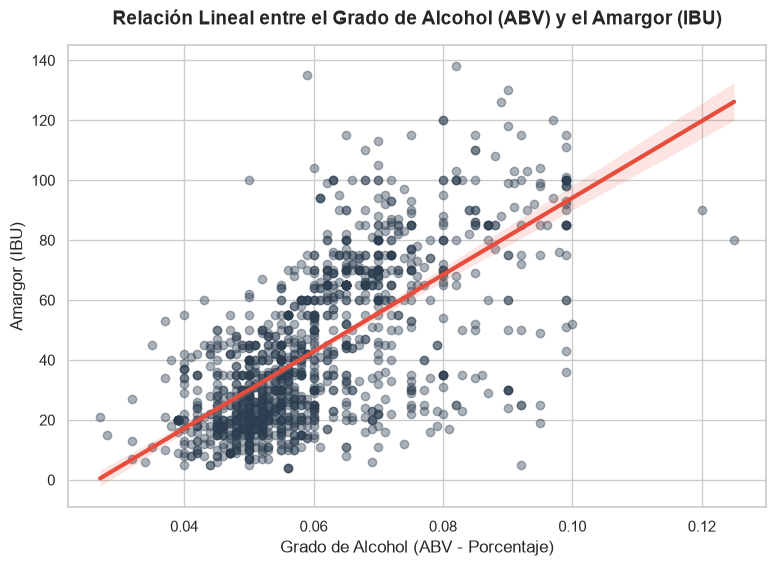

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular la correlación entre ABV e IBU (omitiendo valores NaN)
correlacion = beers['abv'].corr(beers['ibu'])
print(f"El coeficiente de correlación de Pearson es: {correlacion:.2f}")

# 2. Configurar el estilo del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6))

# 3. Pintar el gráfico de dispersión con línea de regresión lineal
sns.regplot(
    data=beers, 
    x='abv', 
    y='ibu', 
    scatter_kws={'alpha':0.4, 'color': '#2c3e50'}, 
    line_kws={'color': '#e74c3c', 'lw': 3}
)

# 4. Personalizar títulos y etiquetas
plt.title('Relación Lineal entre el Grado de Alcohol (ABV) y el Amargor (IBU)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grado de Alcohol (ABV - Porcentaje)', fontsize=12)
plt.ylabel('Amargor (IBU)', fontsize=12)

# Mostrar el gráfico
plt.show()

## Ejercicio 13
Representa el nivel de alcohol (columna `abv`) en un histograma. ¿Se trata de una distribución simétrica o asimétrica?

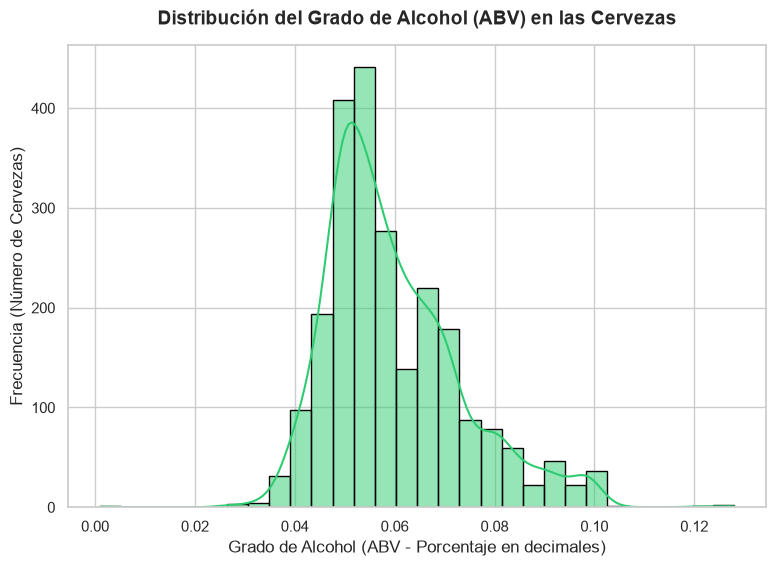

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configurar el estilo y tamaño del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6))

# 2. Pintar el histograma con la curva de densidad (KDE)
sns.histplot(data=beers, x='abv', bins=30, kde=True, color='#2ecc71', edgecolor='black')

# 3. Personalizar títulos y etiquetas
plt.title('Distribución del Grado de Alcohol (ABV) en las Cervezas', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grado de Alcohol (ABV - Porcentaje en decimales)', fontsize=12)
plt.ylabel('Frecuencia (Número de Cervezas)', fontsize=12)

# Mostrar el gráfico
plt.show()


## Ejercicio 14
Representa mediante un *boxplot* de `seaborn` la variable `abv`

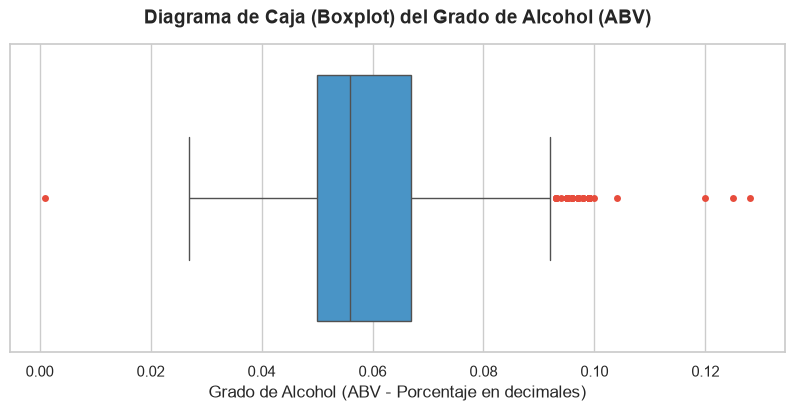

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configurar el estilo del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

# 2. Pintar el boxplot en orientación horizontal
sns.boxplot(
    data=beers, 
    x='abv', 
    color='#3498db', 
    fliersize=5,
    flierprops={'markerfacecolor': '#e74c3c', 'marker': 'o', 'markeredgecolor': 'none'}
)

# 3. Personalizar títulos y etiquetas
plt.title('Diagrama de Caja (Boxplot) del Grado de Alcohol (ABV)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grado de Alcohol (ABV - Porcentaje en decimales)', fontsize=12)

# Mostrar el gráfico
plt.show()


## Ejercicio 15
1. ¿Qué estilos son los que tienen en media más alcohol?
2. ¿Y los estilos que son en media más amargos?

In [50]:
# Filtrar estilos con al menos 10 cervezas para mayor consistencia
estilos_comunes = beers['style'].value_counts()[beers['style'].value_counts() >= 10].index
beers_filtrado = beers[beers['style'].isin(estilos_comunes)]

# Calcular los estilos con más alcohol en media
beers_filtrado.groupby('style')['abv'].mean().sort_values(ascending=False).head(5)

style
Russian Imperial Stout            0.097636
American Double / Imperial IPA    0.087369
Tripel                            0.086818
American Strong Ale               0.076538
Scotch Ale / Wee Heavy            0.076267
Name: abv, dtype: float64

In [51]:
# Calcular los estilos más amargos en media (usando el mismo filtro)
beers_filtrado.groupby('style')['ibu'].mean().sort_values(ascending=False).head(5)

style
American Double / Imperial IPA    93.320000
Russian Imperial Stout            86.500000
American Black Ale                68.900000
American IPA                      67.634551
American Strong Ale               65.416667
Name: ibu, dtype: float64

## Ejercicio 16
Carga el datasets de cervecerias `datasets_breweries.csv`

In [53]:
breweries_file_path = os.path.join(path, "breweries.csv")
breweries = pd.read_csv(breweries_file_path, sep=",")
breweries

,Unnamed: 0,name,city,state
0,0,NorthGate Brewing,Minneapolis,MN
1,1,Against the Grain Brewery,Louisville,KY
2,2,Jack's Abby Craft Lagers,Framingham,MA
3,3,Mike Hess Brewing Company,San Diego,CA
4,4,Fort Point Beer Company,San Francisco,CA
...,...,...,...,...
553,553,Covington Brewhouse,Covington,LA
554,554,Dave's Brewfarm,Wilson,WI
555,555,Ukiah Brewing Company,Ukiah,CA
556,556,Butternuts Beer and Ale,Garrattsville,NY


## Ejercicio 17
1. Renombra la columna `Unnamed: 0` como `brewery_id`
2. Renombra también la columna `name` por `brewery_name`. ¿Puedes hacer ambos apartados en una sola sentencia?

In [ ]:
breweries.rename(columns={'Unnamed: 0': 'brewery_id', 'name': 'brewery_name'}, inplace=True)

In [55]:
breweries

,brewery_id,brewery_name,city,state
0,0,NorthGate Brewing,Minneapolis,MN
1,1,Against the Grain Brewery,Louisville,KY
2,2,Jack's Abby Craft Lagers,Framingham,MA
3,3,Mike Hess Brewing Company,San Diego,CA
4,4,Fort Point Beer Company,San Francisco,CA
...,...,...,...,...
553,553,Covington Brewhouse,Covington,LA
554,554,Dave's Brewfarm,Wilson,WI
555,555,Ukiah Brewing Company,Ukiah,CA
556,556,Butternuts Beer and Ale,Garrattsville,NY


## Ejercicio 18
Junta los dos datasets que tienes

In [57]:
# Fusionar los datasets de cervezas y fábricas usando la columna común
df_cervezas_completo = pd.merge(beers, breweries, on='brewery_id', suffixes=('_beer', '_brewery'))
df_cervezas_completo

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0,10 Barrel Brewing Company,Bend,OR
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
...,...,...,...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0,Wynkoop Brewing Company,Denver,CO
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0,Wynkoop Brewing Company,Denver,CO
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0,Wynkoop Brewing Company,Denver,CO


## Ejercicio 19
1. ¿Cuántos estados diferentes hay?
2. ¿Y ciudades diferentes?
3. ¿Cuántas cervecerías hay?

In [ ]:
# Contar los valores únicos de estados, ciudades y cervecerías
print("Estados únicos:", df_cervezas_completo['state'].nunique())
print("Ciudades únicas:", df_cervezas_completo['city'].nunique())
print("Cervecerías únicas:", df_cervezas_completo['brewery_id'].nunique())

Estados únicos: 51
Ciudades únicas: 384
Cervecerías únicas: 558


## Ejercicio 20
Agrupa por estado y ciudad, la media, mediana y máximo nivel de alcohol

In [ ]:
alcohol_por_ubicacion = df_cervezas_completo.groupby(['state', 'city'])['abv'].agg(['mean', 'median', 'max'])

alcohol_por_ubicacion.head(10)

mean  median    max
state city                               
AK    Anchorage   0.054200  0.0520  0.063
      Juneau      0.053000  0.0530  0.053
      Soldotna    0.058500  0.0580  0.068
      Talkeetna   0.059500  0.0585  0.065
AL    Birmingham  0.065400  0.0600  0.093
      Gadsden     0.060000  0.0600  0.060
      Huntsville  0.057667  0.0510  0.072
AR    Rogers      0.040000  0.0400  0.040
      Springdale  0.055000  0.0545  0.061
AZ    Chandler    0.063158  0.0550  0.095

## Ejercicio 21
¿Cuáles son las cervezas más amargas que se consumen en Indiana, estado = `IN`?

In [61]:
cervezas_indiana = df_cervezas_completo[
    (df_cervezas_completo['state'].str.strip() == 'IN') & 
    (df_cervezas_completo['ibu'].notna())
]

top_amargas_in = cervezas_indiana[['name', 'style', 'city', 'ibu']].sort_values(by='ibu', ascending=False)

top_amargas_in.head(5)

,name,style,city,ibu
479,Hopkick Dropkick,American Double / Imperial IPA,Michigan City,115.0
2191,Overlord Imperial IPA,American Double / Imperial IPA,Evansville,115.0
811,Half Cycle IPA,American IPA,Indianapolis,104.0
2062,Isis,American Double / Imperial IPA,Indianapolis,91.0
2189,Csar,Russian Imperial Stout,Evansville,90.0


## Ejercicio 22
Obtén una tabla con los principales estadísticos del campo `ibu`,  a nivel ciudad

In [62]:
estadisticos_ibu_ciudad = df_cervezas_completo.groupby('city')['ibu'].describe()

estadisticos_ibu_ciudad.head(10)

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Abingdon,1.0,135.000000,NaN,135.0,135.00,135.0,135.00,135.0
Abita Springs,3.0,27.333333,21.455380,13.0,15.00,17.0,34.50,52.0
Ada,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Afton,4.0,43.000000,19.899749,22.0,28.00,45.0,60.00,60.0
Airway Heights,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albuquerque,4.0,54.250000,38.887659,15.0,26.25,51.0,79.00,100.0
Alpine,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Anchorage,10.0,40.400000,26.563132,10.0,15.50,42.5,63.25,70.0
Angola,2.0,19.000000,15.556349,8.0,13.50,19.0,24.50,30.0


## Ejercicio 23
Consigue en un DataFrame de todas las cervezas en cuyas cervecerías al menos haya una cerveza con un `abv` mínimo 0.07.

In [63]:
# 1. Encontrar los IDs únicos de las cervecerías que tienen al menos una cerveza con ABV >= 0.07
cervecerias_potentes = df_cervezas_completo[df_cervezas_completo['abv'] >= 0.07]['brewery_id'].unique()

# 2. Filtrar el DataFrame original para quedarnos con todas las cervezas de esas cervecerías
df_resultado = df_cervezas_completo[df_cervezas_completo['brewery_id'].isin(cervecerias_potentes)]

df_resultado

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
5,0.077,NaN,2261,Black Exodus,Oatmeal Stout,177,12.0,18th Street Brewery,Gary,IN
...,...,...,...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0,Wynkoop Brewing Company,Denver,CO
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0,Wynkoop Brewing Company,Denver,CO
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0,Wynkoop Brewing Company,Denver,CO


## Ejercicio 24
Teniendo en cuenta la media de amargor de todas las cervezas, obtén una tabla con las cervezas cuyos estados tengan una media de amargor en cerveza por encima de la media

In [64]:
# 1. Calcular la media de amargor global (de todas las cervezas)
media_global_ibu = df_cervezas_completo['ibu'].mean()
print(f"La media global de amargor es: {media_global_ibu:.2f} IBUs\n")

# 2. Calcular la media de amargor por cada estado
media_ibu_por_estado = df_cervezas_completo.groupby('state')['ibu'].mean()

# 3. Identificar los estados que están por encima de la media global
estados_sobre_la_media = media_ibu_por_estado[media_ibu_por_estado > media_global_ibu].index

# 4. Obtener la tabla final filtrando las cervezas de esos estados
cervezas_estados_amargos = df_cervezas_completo[df_cervezas_completo['state'].isin(estados_sobre_la_media)]

cervezas_estados_amargos

La media global de amargor es: 42.71 IBUs



,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0,10 Barrel Brewing Company,Bend,OR
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
...,...,...,...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0,Wynkoop Brewing Company,Denver,CO
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0,Wynkoop Brewing Company,Denver,CO
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0,Wynkoop Brewing Company,Denver,CO
